# Dry Bean Classification and Selective Human Review
**Author:** Violetta Kalinicheva  
**Analysis date:** November 9, 2026  
**Modified by:** Violetta Kalinicheva — portfolio documentation, November 16, 2026

## 1. Question and decision
I ask how accurately the seven supplied variety labels can be distinguished, and how many labels remain automatic under a validation-selected referral policy. This internal benchmark informs a model/policy choice for future external evaluation, not deployment or seed-quality certification. The observation is one released row of image-derived measurements.

I preserve the prespecified group-safe split and original frozen results. `analysis.py` contains the inspectable implementation; `protocol.json` records the design fixed before candidate fits. The saved outputs below were executed using the preserved model and prediction cache; a cached replay does not refit or make new test predictions. No original photographs or farm/batch identifiers are available.

The frozen 5% criterion applies to **observed validation errors among accepted rows**, not a population guarantee. A referral withholds an automatic label; human corrections and costs are not observed.

In [1]:
from pathlib import Path
import json
import pandas as pd
import subprocess
import sys
from IPython.display import display, Image
import analysis as a

# I check the original cache before replaying the frozen analysis.
required_cache = ['freeze.json', 'frozen_model.joblib', 'test_receipt.json',
                  'test_predictions.csv', 'model_selection.json', 'cv_summary.csv']
assert all((Path('results') / name).is_file() for name in required_cache), (
    'Keep the supplied results folder intact for cached replay. See README.md.')
print(json.dumps(json.loads(Path('protocol.json').read_text()), indent=2))
checked = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                         text=True, capture_output=True, check=True)
print(checked.stdout + checked.stderr)


{
  "status": "Prespecified before Milestone 2 candidate fitting or final-test predictions",
  "specified_local_date": "2026-11-09",
  "source_arff_sha256": "b2a4a76a2aedfb8ed415adfc1bfc70b5f202cb00cb72e500766e364c14834014",
  "source_archive_sha256": "0a64eff5be87f48c3dbbfc0a12a56c5d5b5167ef8e61cd45d69b3e7c7130c06f",
  "outer_split": {
    "seed": 680,
    "algorithm": "Exact Milestone 1: class-sorted unique-vector groups, default_rng shuffle, array_split into 5; fold0=test, fold1=threshold_validation, folds2-4=train",
    "rows": [
      8163,
      2725,
      2723
    ]
  },
  "inner_cv": {
    "method": "StratifiedGroupKFold",
    "folds": 5,
    "shuffle": true,
    "seed": 68002
  },
  "candidate_grid": {
    "logistic": {
      "preparation": "StandardScaler fitted within each fold",
      "C": [
        0.1,
        1.0,
        10.0,
        100.0
      ],
      "solver": "lbfgs",
      "max_iter": 2000,
      "tol": 0.0001,
      "class_weight": null
    },
    "random_fores

test_all_correct_accept_all (test_analysis.ReferralTests.test_all_correct_accept_all) ... ok
test_all_referred_bootstrap_is_undefined_not_zero (test_analysis.ReferralTests.test_all_referred_bootstrap_is_undefined_not_zero) ... ok
test_all_wrong_refer_all (test_analysis.ReferralTests.test_all_wrong_refer_all) ... ok
test_complete_mixed_tie_not_partial (test_analysis.ReferralTests.test_complete_mixed_tie_not_partial) ... ok
test_csv_round_trip_at_boundary (test_analysis.ReferralTests.test_csv_round_trip_at_boundary) ... ok
test_exact_five_percent (test_analysis.ReferralTests.test_exact_five_percent) ... ok
test_exhaustive_nonmonotonic_scan (test_analysis.ReferralTests.test_exhaustive_nonmonotonic_scan) ... ok
test_full_precision_boundary (test_analysis.ReferralTests.test_full_precision_boundary) ... ok
test_invalid_scores_rejected (test_analysis.ReferralTests.test_invalid_scores_rejected) ... ok
test_row_order_invariant (test_analysis.ReferralTests.test_row_order_invariant) ... ok
test_z

## 2. Source integrity, cleaning, and separation
I parse the preserved ARFF directly from the supplied ZIP after checking both SHA-256 hashes. I check dimensions, labels, numeric types, missing/nonfinite cells, duplicate vectors, conflicting labels, ranges, and five reproducible geometry relationships. I retain all rows and raw feature names. No joins, missing-value imputations, removals, or undocumented unit conversions are performed.

I group identical 16-feature vectors before the exact seeded class-wise split. The outer test and threshold-validation sets do not enter fitting or model selection. Five grouped folds subdivide training only. The split checks do not establish independent biological seeds, farms, harvests, or cameras.

In [2]:
state = a.audit_and_split()
display(pd.DataFrame(state['audit']['splits']).drop(columns='class_counts'))
display(pd.Series(state['audit']['class_counts'], name='supplied_rows').to_frame())
print(json.dumps(a.load_json('environment.json'), indent=2))


Audit passed: 13,611 rows; 13,543 vectors; no split overlap.


,partition,rows,groups
0,train,8163,8121
1,validation,2725,2710
2,test,2723,2712


,supplied_rows
BARBUNYA,1322
BOMBAY,522
CALI,1630
DERMASON,3546
HOROZ,1928
SEKER,2027
SIRA,2636


{
  "python": "3.12.14",
  "numpy": "2.3.5",
  "pandas": "2.2.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "joblib": "1.6.0",
  "threadpoolctl": "3.7.0",
  "nbformat": "5.11.1",
  "nbclient": "0.11.0",
  "ipykernel": "7.3.0"
}


## 3. Training-only candidate comparison
I compare four scaled regularized multinomial logistic regressions (C = 0.1, 1, 10, 100) with four bounded random forests (200 trees; depths 8 or 12; minimum leaves 2 or 5). Scaling is learned separately within each fold, never before the split. I select the highest mean five-fold macro-F1, averaging all seven class-specific F1 scores equally. The saved tie rule resolves scores within 1e-12 of the global maximum.

Logistic regression provides a compact linear boundary; the forest tests nonlinear alternatives with constrained complexity. A training-majority baseline tests whether useful classification exceeds simply using the largest class. Fold SD describes variation across these folds; it is not a confidence interval. The small grid limits schedule and search risk. SVM, calibration, feature selection, and further search remain future options requiring a new validation design.

In [3]:
cv_summary = a.compare_models(state)
display(cv_summary)
print('Selected:', state['selected'])


Reusing prespecified training-CV results; no new model search.


,candidate,mean_macro_f1,sd_macro_f1,mean_accuracy
0,LR_C0.1,0.933588,0.004572,0.922332
1,LR_C1,0.934175,0.003552,0.922822
2,LR_C10,0.934649,0.005588,0.923679
3,LR_C100,0.936599,0.004529,0.925517
4,RF_d8_leaf2,0.927926,0.005847,0.918536
5,RF_d8_leaf5,0.928126,0.005367,0.919025
6,RF_d12_leaf2,0.932140,0.005246,0.921475
7,RF_d12_leaf5,0.931809,0.005580,0.921598
8,Majority,0.059059,0.000051,0.260566


Selected: {'id': 'LR_C100', 'kind': 'logistic', 'C': 100.0, 'tie_rank': [0, 100.0, 0]}


## 4. Fit once and freeze the validation referral rule
I fit only the selected configuration on the full 60% training partition. Maximum class scores rank cases, but I do not call them calibrated correctness probabilities. I enumerate 0 and every distinct validation score, accepting score ≥ cutoff, with ties kept whole. A nonempty candidate is feasible when `20 * accepted_errors <= accepted_count`. I choose greatest accepted count, then smallest cutoff. Error need not decrease monotonically, so the scan is exhaustive.

If no nonempty rule is feasible, the explicit fallback refers all rows and conditional error is undefined. I save the exact score cutoff and fitted-model hash before test predictions. I do not refit on training plus validation.

In [4]:
freeze = a.freeze_policy(state)
print(json.dumps(freeze, indent=2))


Reusing original frozen model and policy; no refit or threshold reselection.


{
  "created_utc": "2026-11-09T21:13:48.593236+00:00",
  "selected": {
    "id": "LR_C100",
    "kind": "logistic",
    "C": 100.0,
    "tie_rank": [
      0,
      100.0,
      0
    ]
  },
  "training_rows": 8163,
  "validation_rows": 2725,
  "policy": {
    "status": "threshold",
    "threshold": 0.6584236272363831,
    "accepted": 2500,
    "errors": 125,
    "coverage": 0.9174311926605505,
    "accepted_error": 0.05
  },
  "model_sha256": "56fdd7d99512eaaffbc4e34d6b048da5d220b0f4733a440d3757a81f7e042722",
  "protocol_sha256": "e06395a55ee637ff989fc26ea582138dceca082c93d9df543c8cf5263b303039",
  "test_predictions_created": false,
  "note": "Frozen before first test prediction. No train-plus-validation refit."
}


## 5. One held-out prediction cache
Only the selected model and training-majority baseline receive test predictions. I predict each exact vector once and expand back to the original rows so equal vectors have identical scores and decisions. I write 17 significant digits and reload with round-trip float parsing; a tested boundary case prevents disk rounding from changing acceptance.

Every later test metric, figure, interval, and weighting sensitivity uses this cache. On exact re-execution, the code reuses the original frozen model, training-CV results, and hash-verified cache without changing the policy. For a from-scratch replication, preserve this folder and run an untouched copy without `results/`; do not adapt the design using known test outcomes.

In [5]:
test_cache = a.evaluate_test(state)
print('Cached rows:', len(test_cache))
display(test_cache[['row_id', 'feature_group', 'actual', 'predicted', 'score', 'accepted']].head())


Held-out cache verified: 2,723 rows. All further test analysis uses this file.


Cached rows: 2723


,row_id,feature_group,actual,predicted,score,accepted
0,1,1,SEKER,SEKER,0.999954,True
1,6,6,SEKER,SEKER,0.999750,True
2,10,10,SEKER,SEKER,0.998474,True
3,12,12,SEKER,SEKER,0.995388,True
4,13,13,SEKER,SEKER,0.989810,True


## 6. Metrics, uncertainty, and evaluation-weight sensitivity
I report full-coverage macro-F1, accuracy, macro recall, confusion counts, and baseline metrics separately from accepted-only error and automatic coverage. All seven classes remain visible; a class with no accepted rows has undefined accepted error, not zero.

For 2,000 seeded percentile bootstrap replicates, I resample entire exact-feature groups with replacement, retaining all member-row multiplicities. The same draws give a paired baseline comparison. Model and cutoff remain fixed. These intervals describe conditional internal-collection sampling variation; they omit fitting/search uncertainty and unidentified batch dependence. Exact-vector groups are a pragmatic dependence control, not known natural clusters.

I also weight each test vector once using the same cache. This checks evaluation weighting, not the training effect of retaining duplicate rows. I do not select an alternate model after seeing test results.

In [6]:
metrics = a.summarize_results()
print(json.dumps(a.load_json('bootstrap.json'), indent=2))
display(pd.read_csv('results/per_class.csv'))
print(json.dumps(a.load_json('sensitivity.json'), indent=2))


{
  "rows": 2723,
  "groups": 2712,
  "full_coverage": {
    "accuracy": 0.9269188395152406,
    "macro_f1": 0.9392476089730906,
    "macro_recall": 0.9384724819088281
  },
  "baseline": {
    "accuracy": 0.2607418288652222,
    "macro_f1": 0.05909034164204569,
    "macro_recall": 0.14285714285714285
  },
  "accepted": 2536,
  "referred": 187,
  "accepted_errors": 124,
  "total_errors": 199,
  "referred_errors": 75,
  "coverage": 0.9313257436650753,
  "accepted_error": 0.04889589905362776,
  "observed_target_met": true
}


   class  support  accepted  referred  referral_rate  accepted_errors  accepted_error  full_precision  full_recall  full_f1
BARBUNYA      265       251        14       0.052830               12        0.047809        0.938697     0.924528 0.931559
  BOMBAY      105       105         0       0.000000                0        0.000000        1.000000     1.000000 1.000000
    CALI      326       295        31       0.095092               12        0.040678        0.949843     0.929448 0.939535
DERMASON      710       652        58       0.081690               36        0.055215        0.914326     0.916901 0.915612
   HOROZ      383       374         9       0.023499                9        0.024064        0.961039     0.966057 0.963542
   SEKER      406       388        18       0.044335               10        0.025773        0.949029     0.963054 0.955990
    SIRA      528       471        57       0.107955               45        0.095541        0.867675     0.869318 0.868496


{
  "replicates": 2000,
  "seed": 68003,
  "method": "Unstratified whole-feature-group resampling with member-row multiplicity",
  "scope": "Conditional on fitted model and validation-selected rule; internal collection only",
  "intervals": {
    "macro_f1": {
      "lower": 0.9304440272792269,
      "upper": 0.9470616710654435,
      "undefined_replicates": 0
    },
    "accuracy": {
      "lower": 0.9164204684459609,
      "upper": 0.9360058845163663,
      "undefined_replicates": 0
    },
    "macro_recall": {
      "lower": 0.9293753182540925,
      "upper": 0.9465714903498759,
      "undefined_replicates": 0
    },
    "macro_f1_gain_over_majority": {
      "lower": 0.8708416407693906,
      "upper": 0.8888865873622906,
      "undefined_replicates": 0
    },
    "coverage": {
      "lower": 0.9215786777322826,
      "upper": 0.9408957415565345,
      "undefined_replicates": 0
    },
    "accepted_error": {
      "lower": 0.04083155083796921,
      "upper": 0.057778308967863665,
  

,class,support,accepted,referred,referral_rate,accepted_errors,accepted_error,full_precision,full_recall,full_f1
0,BARBUNYA,265,251,14,0.052830,12,0.047809,0.938697,0.924528,0.931559
1,BOMBAY,105,105,0,0.000000,0,0.000000,1.000000,1.000000,1.000000
2,CALI,326,295,31,0.095092,12,0.040678,0.949843,0.929448,0.939535
3,DERMASON,710,652,58,0.081690,36,0.055215,0.914326,0.916901,0.915612
4,HOROZ,383,374,9,0.023499,9,0.024064,0.961039,0.966057,0.963542
5,SEKER,406,388,18,0.044335,10,0.025773,0.949029,0.963054,0.955990
6,SIRA,528,471,57,0.107955,45,0.095541,0.867675,0.869318,0.868496


{
  "primary_row_weighted": {
    "rows": 2723,
    "groups": 2712,
    "full_coverage": {
      "accuracy": 0.9269188395152406,
      "macro_f1": 0.9392476089730906,
      "macro_recall": 0.9384724819088281
    },
    "baseline": {
      "accuracy": 0.2607418288652222,
      "macro_f1": 0.05909034164204569,
      "macro_recall": 0.14285714285714285
    },
    "accepted": 2536,
    "referred": 187,
    "accepted_errors": 124,
    "total_errors": 199,
    "referred_errors": 75,
    "coverage": 0.9313257436650753,
    "accepted_error": 0.04889589905362776,
    "observed_target_met": true
  },
  "one_per_vector": {
    "rows": 2712,
    "groups": 2712,
    "full_coverage": {
      "accuracy": 0.926622418879056,
      "macro_f1": 0.9390940120115177,
      "macro_recall": 0.9383290993641991
    },
    "baseline": {
      "accuracy": 0.2617994100294985,
      "macro_f1": 0.05928028721716623,
      "macro_recall": 0.14285714285714285
    },
    "accepted": 2525,
    "referred": 187,
    "acce

### Observed results and decision
The training-selected logistic model (C = 100) reached full-test macro-F1 **0.9392**, accuracy **92.69%**, and macro recall **93.85%**. The majority baseline had macro-F1 **0.0591** and accuracy **26.07%**. SIRA–DERMASON exchanges account for **100 of 199** full-coverage errors.

The frozen cutoff **0.6584236272363831** accepted **2,536/2,723** test rows (**93.13%**) with **124/2,536 errors (4.89%)**. The conditional 95% group-bootstrap error interval is **4.08–5.78%**, crossing the provisional 5% target. Referring 187 rows withheld 75 erroneous and 112 correct predictions; those are model outcomes, not observed human corrections.

Among true supplied labels, SIRA has **45/471 accepted errors (9.55%)**, and DERMASON **36/652 (5.52%)**. Aggregate compliance does not imply class-wise compliance. The smallest class, BOMBAY, has 0/105 referrals and 0/105 accepted errors, which is not proof of zero population risk. One-per-vector test weighting gives macro-F1 **0.9391**, coverage **93.10%**, and accepted error **4.91%**; no training sensitivity was performed.

I retain this as an internal benchmark for independent validation. I do not recommend deployment or test-driven retuning. `results/per_class.csv` and `results/bootstrap.json` retain the class denominators and uncertainty that qualify the aggregate result.

## 7. Five evidence-led illustrations
1. Class support and training-only morphology: source balance and potential overlap.
2. Training-only grouped CV: model-selection evidence, not test ranking.
3. Held-out confusion matrix: counts, percentages, and all class denominators.
4. Validation error–coverage curve plus one frozen test point: no test threshold sweep.
5. Per-class referrals and accepted errors: unequal burden remains visible.


Five figures created from verified audit, training folds, and cached predictions.


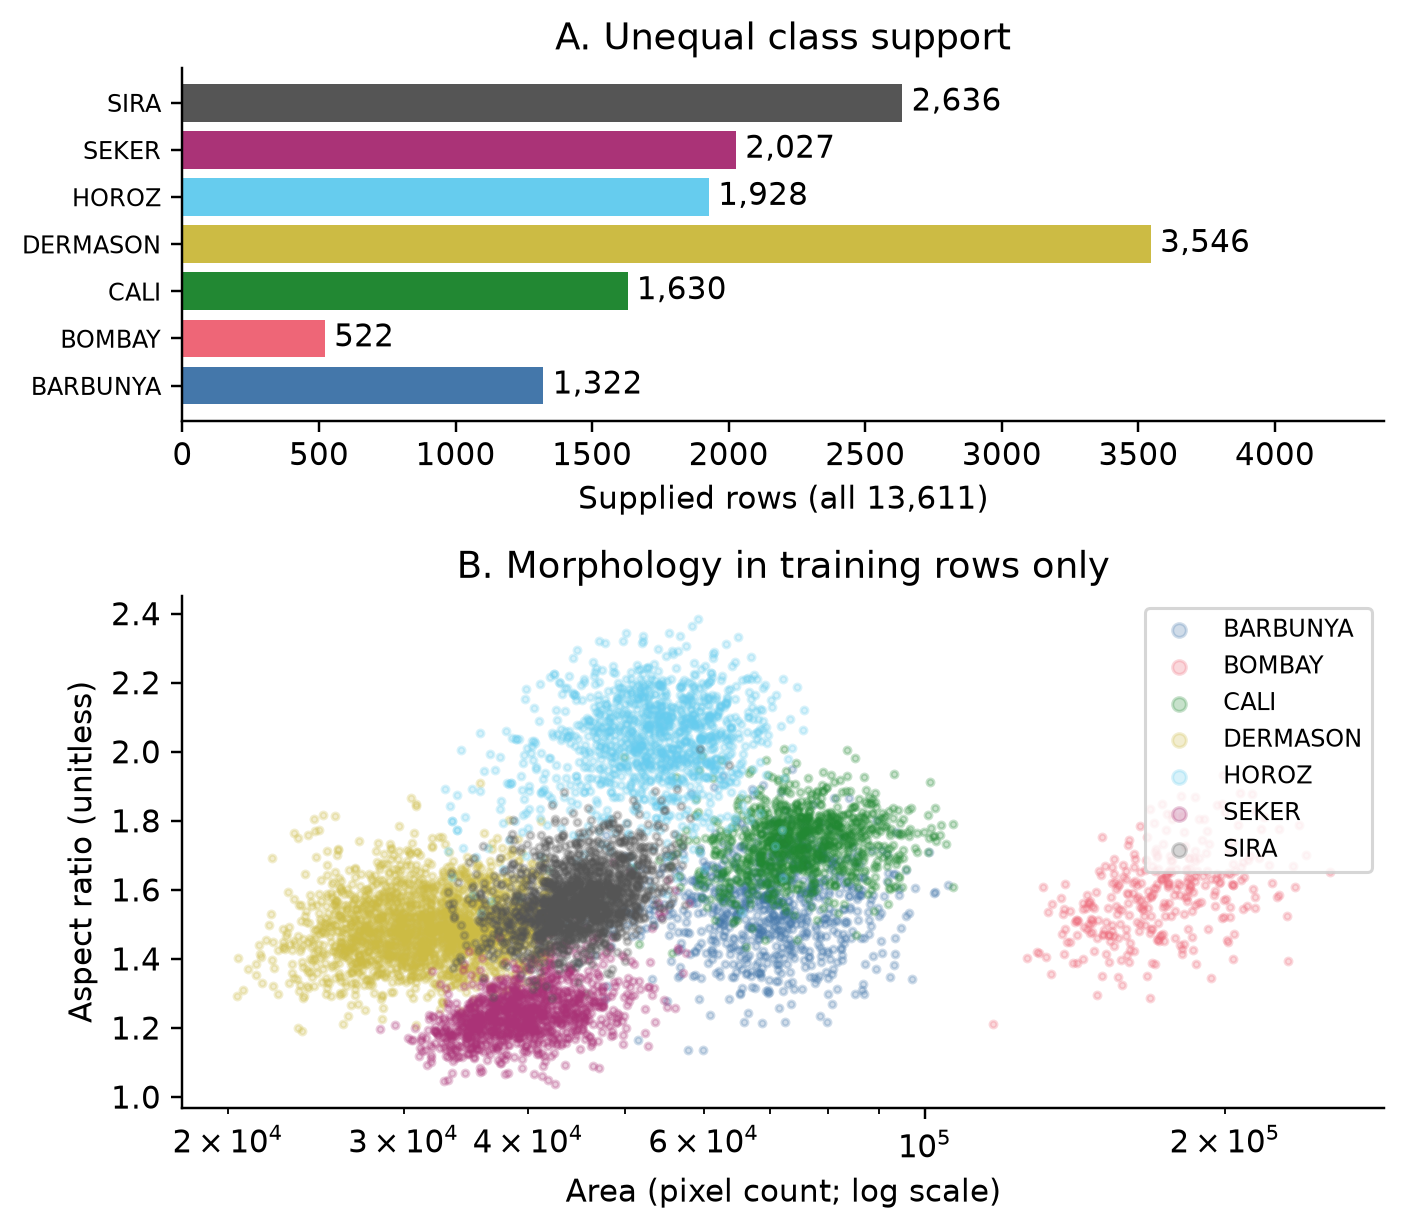

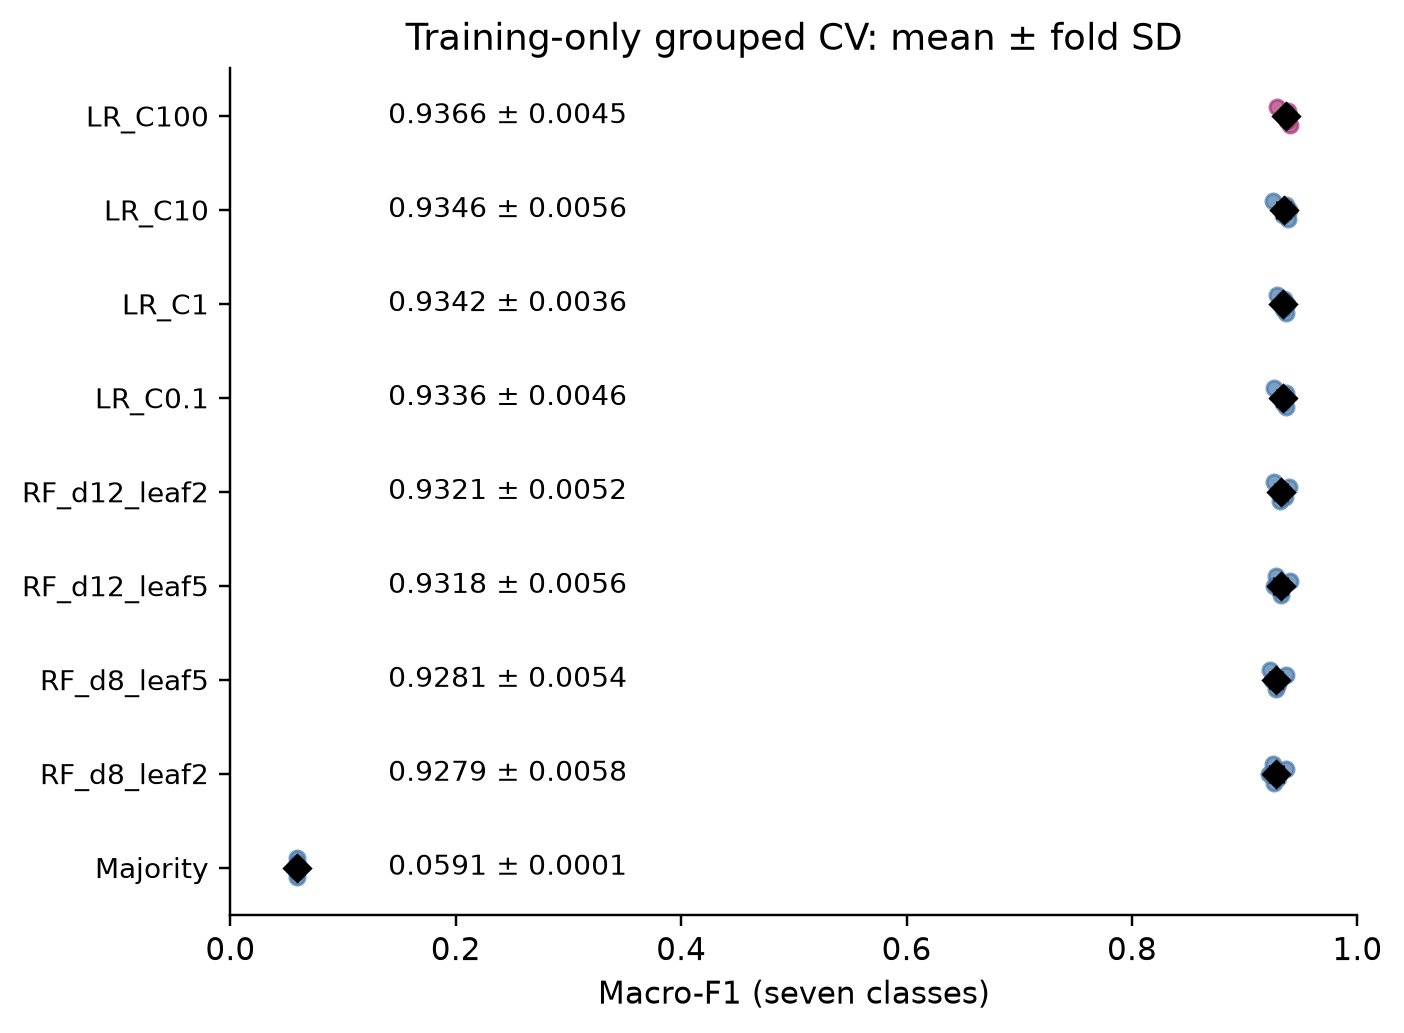

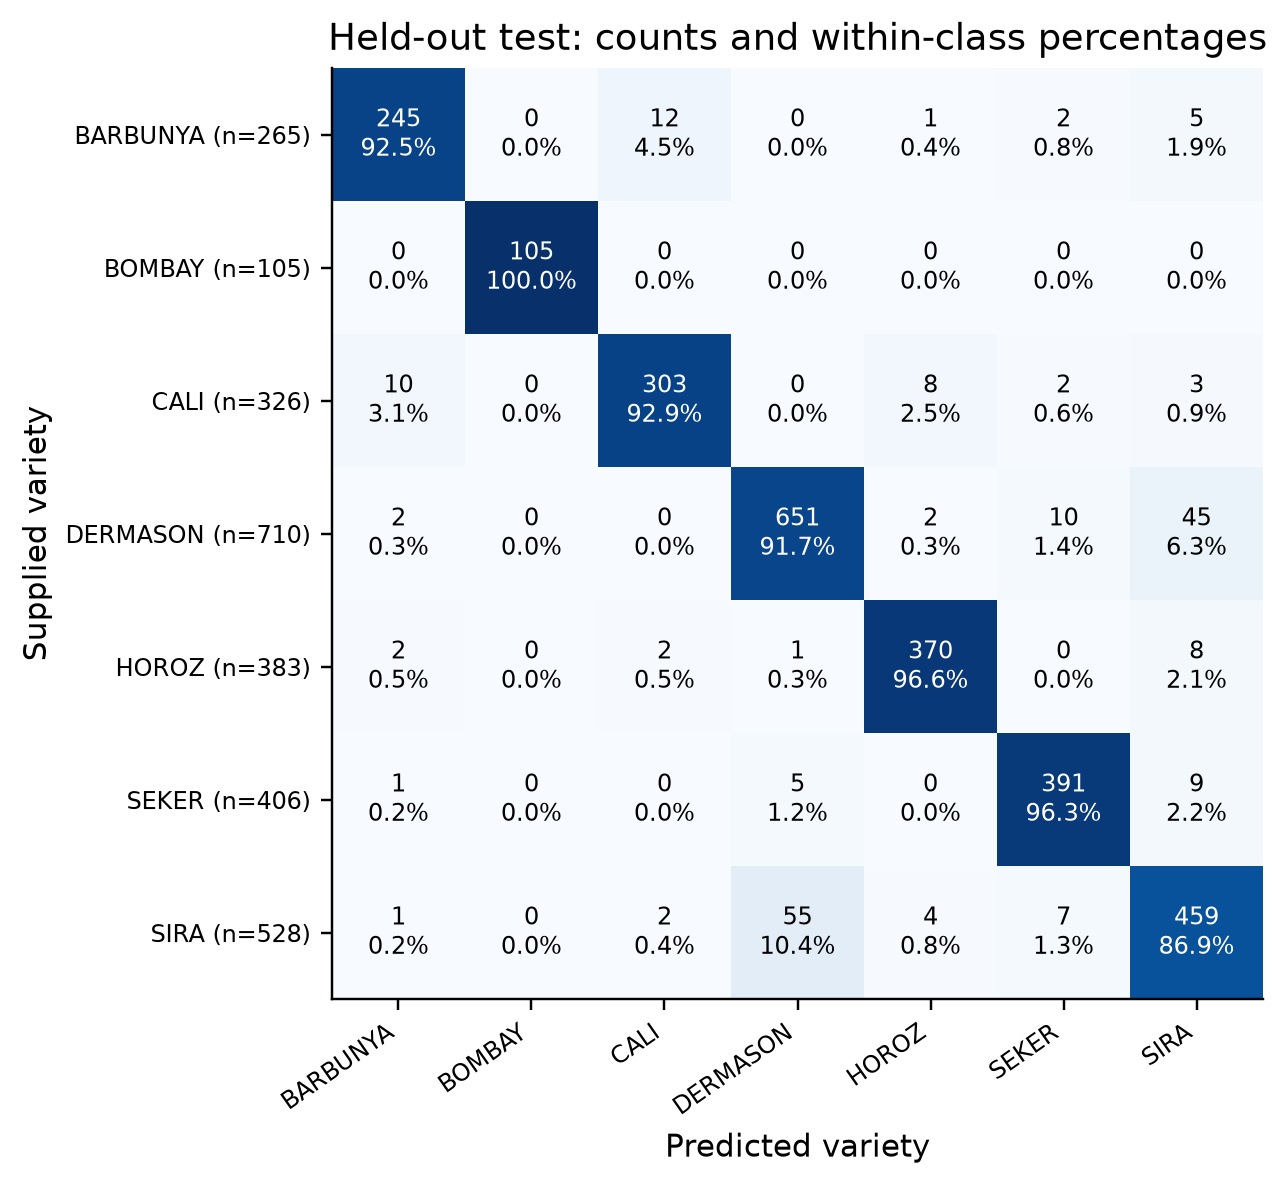

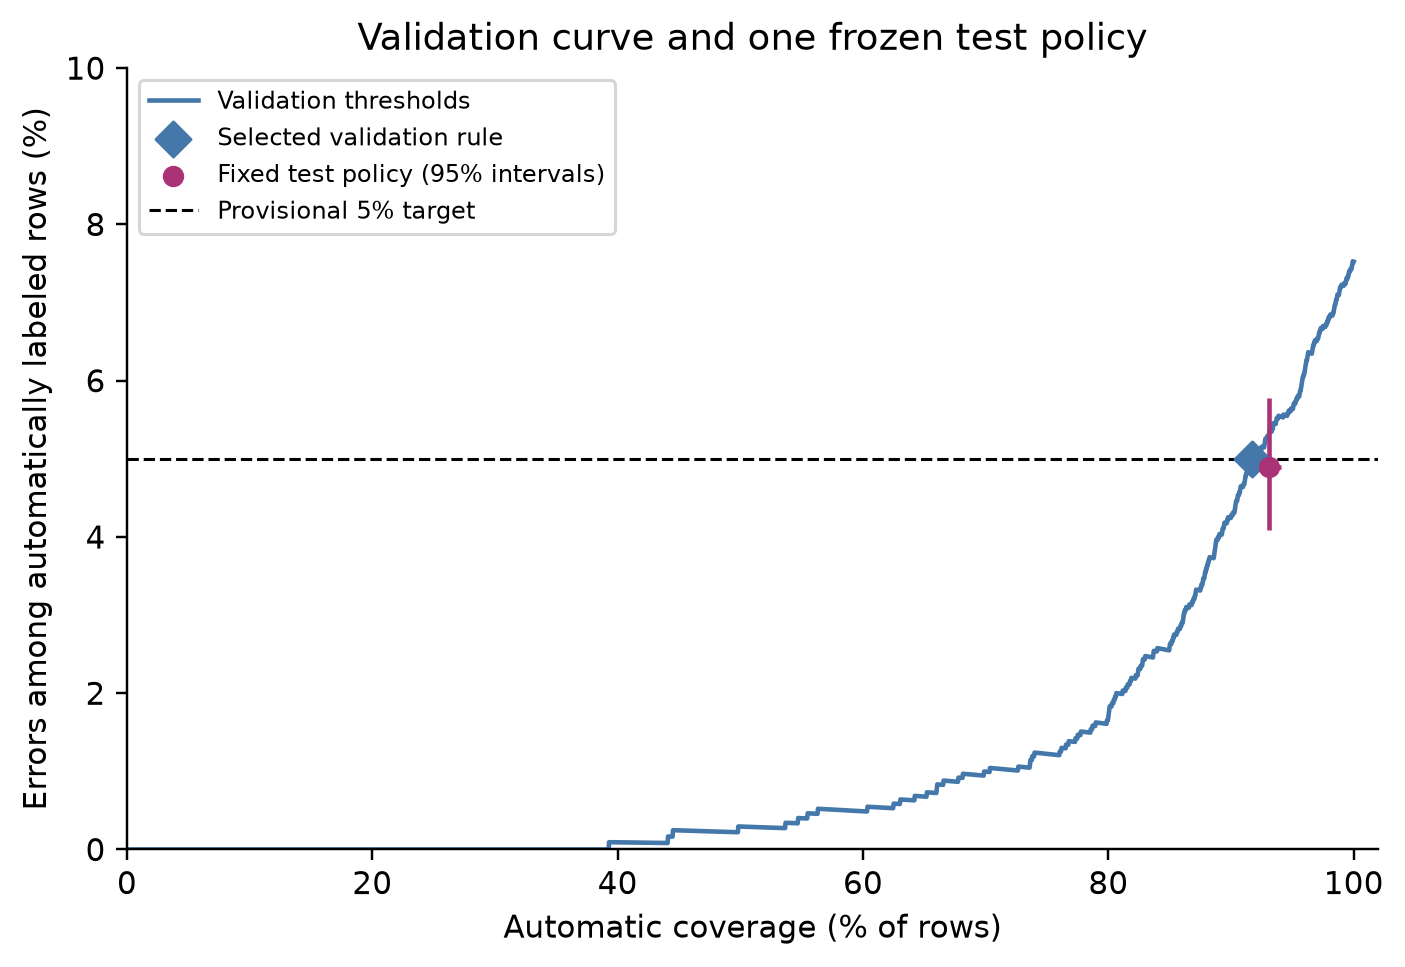

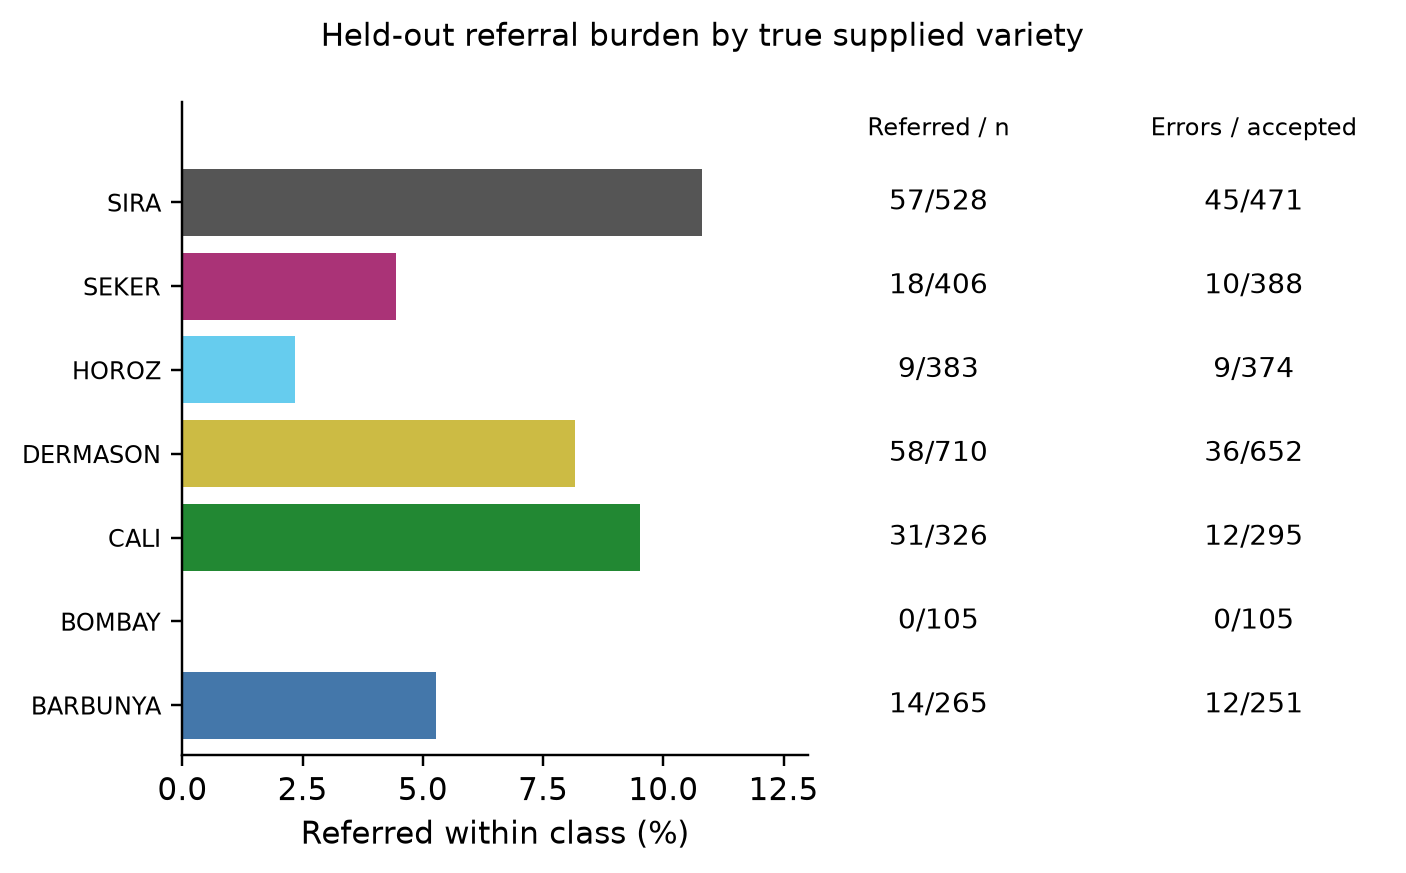

In [7]:
a.plot_results(state)
for number in range(1, 6):
    display(Image(filename=f'figures/figure_{number}.png'))


## 8. Interpretation, limitations, and next decision
The observed outputs support an internal classification and referral benchmark, not deployment. No future-farm performance, human correction, labor savings, safety, or causal effects are inferred. The 5% target is provisional; if held-out error exceeds it, that failure must be retained, not repaired through test-driven retuning.

Before operational use, obtain authorized independent batch/camera/harvest data, confirm label and measurement definitions, agree on class-specific error tolerance and review capacity, evaluate calibration with a separate fitting-safe design if needed, and measure real review outcomes. Nonpersonal benchmark data reduces privacy concerns but does not remove provenance, representativeness, licensing, or overclaiming risks.

### Sources and attribution
- UCI Machine Learning Repository. (2020). *Dry bean* [Data set]. https://doi.org/10.24432/C50S4B. Retrieved November 3, 2026; documentation/license checked November 9, 2026. CC BY 4.0: https://creativecommons.org/licenses/by/4.0/.
- Köklü, M., & Özkan, I. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. *Computers and Electronics in Agriculture, 174*, 105507. https://doi.org/10.1016/j.compag.2020.105507. Author-hosted abstract reviewed; full publisher methods not verified.
- Geifman, Y., & El-Yaniv, R. (2017). Selective classification for deep neural networks. *Advances in Neural Information Processing Systems, 30*, 4878–4887. https://arxiv.org/abs/1705.08500. Error–coverage framing only; this project does not implement SGR's guarantee.
- Scikit-learn developers. (n.d.). *StratifiedGroupKFold; LogisticRegression; f1_score; probability calibration*. https://scikit-learn.org/stable/. Documentation checked November 9, 2026.

Raw archive unchanged; derived group assignments, predictions, metrics, and figures are original analysis products. See `ATTRIBUTION.txt`, `LICENSE`, and `README.md`. The historical protocol retains milestone labels solely to preserve its exact hash chain. Only load trusted local joblib files; untrusted serialized models can execute code.